In [1]:
# ============================================================================
# Instalacao das bibliotecas (executar apenas uma vez)
# ============================================================================
# !pip install imbalanced-learn optuna scikit-learn pandas matplotlib seaborn scipy

In [2]:
import time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import (train_test_split, RandomizedSearchCV,
                                     StratifiedKFold, cross_val_score)
from sklearn.experimental import enable_iterative_imputer   # habilita o IterativeImputer
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, ExtraTreesRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
from scipy.stats import randint

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)
sns.set_style('whitegrid')

SEED = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
METRICA = 'f1'      # F1 da classe minoritaria (sobreviventes)
print('Ambiente pronto.')

Ambiente pronto.


/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
base = pd.read_csv('titanic_completo.csv')
base = base.dropna(how='all')                 # descarta a ultima linha vazia do arquivo
base['survived'] = base['survived'].astype(int)
base['pclass']   = base['pclass'].astype(int)

print('Dimensoes da base.........:', base.shape)
print('\nTipos de cada atributo:')
print(base.dtypes)
print('\nDistribuicao da classe (survived):')
print(base['survived'].value_counts())
print((base['survived'].value_counts(normalize=True) * 100).round(1))

Dimensoes da base.........: (1309, 14)

Tipos de cada atributo:
pclass         int64
survived       int64
name             str
sex              str
age          float64
sibsp        float64
parch        float64
ticket           str
fare         float64
cabin            str
embarked         str
boat             str
body         float64
home.dest        str
dtype: object

Distribuicao da classe (survived):
survived
0    809
1    500
Name: count, dtype: int64
survived
0    61.8
1    38.2
Name: proportion, dtype: float64


In [4]:
ausentes = pd.DataFrame({
    'ausentes'  : base.isna().sum(),
    'percentual': (base.isna().sum() / len(base) * 100).round(2)
}).sort_values('ausentes', ascending=False)
print('Valores ausentes por atributo:')
print(ausentes)
print('\nLinhas 100% preenchidas:', base.dropna().shape[0])

Valores ausentes por atributo:
           ausentes  percentual
body           1188       90.76
cabin          1014       77.46
boat            823       62.87
home.dest       564       43.09
age             263       20.09
embarked          2        0.15
fare              1        0.08
sibsp             0        0.00
name              0        0.00
survived          0        0.00
pclass            0        0.00
sex               0        0.00
parch             0        0.00
ticket            0        0.00

Linhas 100% preenchidas: 0


In [5]:
print('Sobrevivencia por sexo:')
print(base.groupby('sex')['survived'].agg(['mean', 'count']).round(3))
print('\nSobrevivencia por classe:')
print(base.groupby('pclass')['survived'].agg(['mean', 'count']).round(3))
print('\nSobrevivencia por porto de embarque:')
print(base.groupby('embarked')['survived'].agg(['mean', 'count']).round(3))

Sobrevivencia por sexo:
         mean  count
sex                 
female  0.727    466
male    0.191    843

Sobrevivencia por classe:
         mean  count
pclass              
1       0.619    323
2       0.430    277
3       0.255    709

Sobrevivencia por porto de embarque:
           mean  count
embarked              
C         0.556    270
Q         0.358    123
S         0.333    914


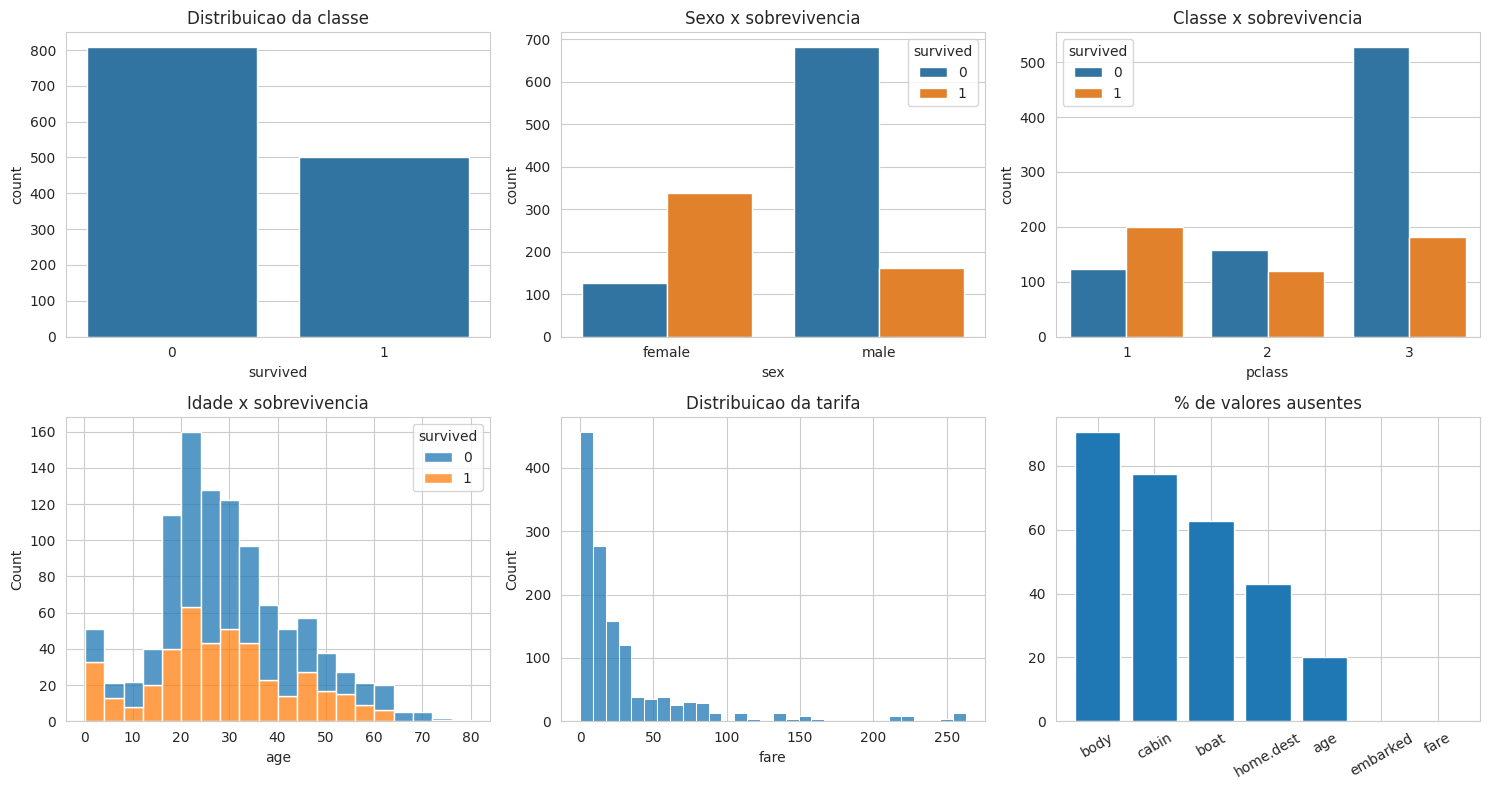

In [6]:
fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
sns.countplot(x=base['survived'], ax=eixos[0, 0]);        eixos[0, 0].set_title('Distribuicao da classe')
sns.countplot(x='sex',    hue='survived', data=base, ax=eixos[0, 1]); eixos[0, 1].set_title('Sexo x sobrevivencia')
sns.countplot(x='pclass', hue='survived', data=base, ax=eixos[0, 2]); eixos[0, 2].set_title('Classe x sobrevivencia')
sns.histplot(data=base, x='age', hue='survived', bins=20, multiple='stack', ax=eixos[1, 0])
eixos[1, 0].set_title('Idade x sobrevivencia')
sns.histplot(data=base[base['fare'] < 300], x='fare', bins=30, ax=eixos[1, 1])
eixos[1, 1].set_title('Distribuicao da tarifa')
eixos[1, 2].bar(ausentes[ausentes['ausentes'] > 0].index,
                ausentes[ausentes['ausentes'] > 0]['percentual'])
eixos[1, 2].set_title('% de valores ausentes'); eixos[1, 2].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

In [7]:
print('Evidencia do vazamento de informacao:')
print(pd.crosstab(base['boat'].notna(), base['survived']))
print()
print(pd.crosstab(base['body'].notna(), base['survived']))

Evidencia do vazamento de informacao:
survived    0    1
boat              
False     800   23
True        9  477

survived    0    1
body              
False     688  500
True      121    0


In [8]:
colunas_removidas = ['boat', 'body', 'cabin', 'home.dest', 'name', 'ticket']
dados = base.drop(columns=colunas_removidas)

# embarked: apenas 2 ausentes e atributo nominal -> moda (nao entra nos imputadores numericos)
moda_emb = dados['embarked'].mode()[0]
dados['embarked'] = dados['embarked'].fillna(moda_emb)
print('embarked preenchido com a moda:', moda_emb)

# Codificacao:
#   sex      -> binario 0/1 (2 valores, entao binario == One-Hot)
#   embarked -> One-Hot (nominal: nao existe ordem entre C, Q e S)
#   pclass   -> inteiro 1 < 2 < 3, pois a ordem e REAL (classe social)
dados['sex'] = (dados['sex'] == 'male').astype(int)          # 0 = feminino, 1 = masculino
dados = pd.get_dummies(dados, columns=['embarked'], dtype=int)

X = dados.drop(columns=['survived'])
y = dados['survived']
COLS = list(X.columns)
print('\nAtributos finais:', COLS)
print('\nAusentes restantes (serao imputados):')
print(X.isna().sum()[X.isna().sum() > 0])

embarked preenchido com a moda: S

Atributos finais: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked_C', 'embarked_Q', 'embarked_S']

Ausentes restantes (serao imputados):
age     263
fare      1
dtype: int64


In [9]:
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)
print('Treino:', X_tr_raw.shape, '| Teste:', X_te_raw.shape)
print('Distribuicao no treino:', dict(y_tr.value_counts()))
print('Distribuicao no teste :', dict(y_te.value_counts()))

Treino: (916, 9) | Teste: (393, 9)
Distribuicao no treino: {0: np.int64(566), 1: np.int64(350)}
Distribuicao no teste : {0: np.int64(243), 1: np.int64(150)}


In [10]:
def imputar(imputador, X_tr, X_te):
    """Ajusta o imputador SO no treino e aplica nos dois conjuntos."""
    esc = MinMaxScaler().fit(X_tr)                       # o KNN depende de escala
    tr = pd.DataFrame(esc.inverse_transform(
        imputador.fit_transform(esc.transform(X_tr))), columns=COLS, index=X_tr.index)
    te = pd.DataFrame(esc.inverse_transform(
        imputador.transform(esc.transform(X_te))), columns=COLS, index=X_te.index)
    return tr, te

t0 = time.perf_counter()
knn = KNNImputer(n_neighbors=5, weights='distance')
Xtr_knn, Xte_knn = imputar(knn, X_tr_raw, X_te_raw)
t_knn = time.perf_counter() - t0

t0 = time.perf_counter()
miss = IterativeImputer(
    estimator=ExtraTreesRegressor(n_estimators=100, random_state=SEED, n_jobs=-1),
    max_iter=10, random_state=SEED, initial_strategy='median')
Xtr_mf, Xte_mf = imputar(miss, X_tr_raw, X_te_raw)
t_mf = time.perf_counter() - t0

print(f'KNN Imputer ajustado em {t_knn:.2f}s | MissForest ajustado em {t_mf:.2f}s')
print('Ausentes apos imputacao:', int(Xtr_knn.isna().sum().sum()), int(Xtr_mf.isna().sum().sum()))

KNN Imputer ajustado em 0.02s | MissForest ajustado em 3.84s
Ausentes apos imputacao: 0 0


In [11]:
def resumo(serie, rotulo):
    s = serie.dropna()
    return {'Conjunto': rotulo, 'n': len(s), 'Media': s.mean(), 'Desvio': s.std(),
            'Min': s.min(), 'Q1': s.quantile(.25), 'Mediana': s.median(),
            'Q3': s.quantile(.75), 'Max': s.max(),
            'Assimetria': stats.skew(s), 'Curtose': stats.kurtosis(s)}

linhas = []
for atr in ['age', 'fare']:
    orig = X_tr_raw[atr]
    linhas.append({'Atributo': atr, **resumo(orig, 'Original (sem ausentes)')})
    for nome, b in [('KNN Imputer', Xtr_knn), ('MissForest', Xtr_mf)]:
        linhas.append({'Atributo': atr, **resumo(b[atr], nome)})
        mask = orig.isna()
        if mask.sum():
            linhas.append({'Atributo': atr,
                           **resumo(b.loc[mask, atr], f'{nome} (so os imputados)')})

tab_dist = pd.DataFrame(linhas).round(3)
print('TABELA 1 - Impacto da imputacao sobre a distribuicao (conjunto de treino)')
print(tab_dist.to_string(index=False))

TABELA 1 - Impacto da imputacao sobre a distribuicao (conjunto de treino)
Atributo                      Conjunto   n  Media  Desvio   Min     Q1  Mediana     Q3     Max  Assimetria  Curtose
     age       Original (sem ausentes) 726 29.820  14.372 0.333 21.000   28.000 39.000  80.000       0.403    0.139
     age                   KNN Imputer 916 30.322  13.972 0.333 21.000   28.829 39.000  80.000       0.350    0.223
     age KNN Imputer (so os imputados) 190 32.237  12.172 4.528 23.505   32.100 38.957  80.000       0.200    0.808
     age                    MissForest 916 29.454  13.510 0.333 21.000   27.737 37.333  80.000       0.426    0.397
     age  MissForest (so os imputados) 190 28.055   9.422 5.962 23.400   26.978 33.438  54.500      -0.011    0.292
    fare       Original (sem ausentes) 915 32.582  49.420 0.000  7.896   14.454 31.275 512.329       4.222   25.506
    fare                   KNN Imputer 916 32.555  49.400 0.000  7.896   14.454 31.275 512.329       4.224   25.53

In [12]:
testes = []
for atr in ['age', 'fare']:
    orig = X_tr_raw[atr].dropna()
    for nome, b in [('KNN Imputer', Xtr_knn), ('MissForest', Xtr_mf)]:
        ks = stats.ks_2samp(orig, b[atr])
        testes.append({'Atributo': atr, 'Metodo': nome,
                       'KS': round(ks.statistic, 4), 'p-valor': round(ks.pvalue, 4),
                       'Wasserstein': round(stats.wasserstein_distance(orig, b[atr]), 4),
                       'Var. do desvio (%)': round((b[atr].std() / orig.std() - 1) * 100, 2)})
tab_ks = pd.DataFrame(testes)
print('TABELA 2 - Teste de Kolmogorov-Smirnov (original x base imputada)')
print(tab_ks.to_string(index=False))

TABELA 2 - Teste de Kolmogorov-Smirnov (original x base imputada)
Atributo      Metodo     KS  p-valor  Wasserstein  Var. do desvio (%)
     age KNN Imputer 0.0667   0.0513       0.7264               -2.78
     age  MissForest 0.0656   0.0577       0.8780               -6.00
    fare KNN Imputer 0.0010   1.0000       0.0275               -0.04
    fare  MissForest 0.0011   1.0000       0.0287               -0.04


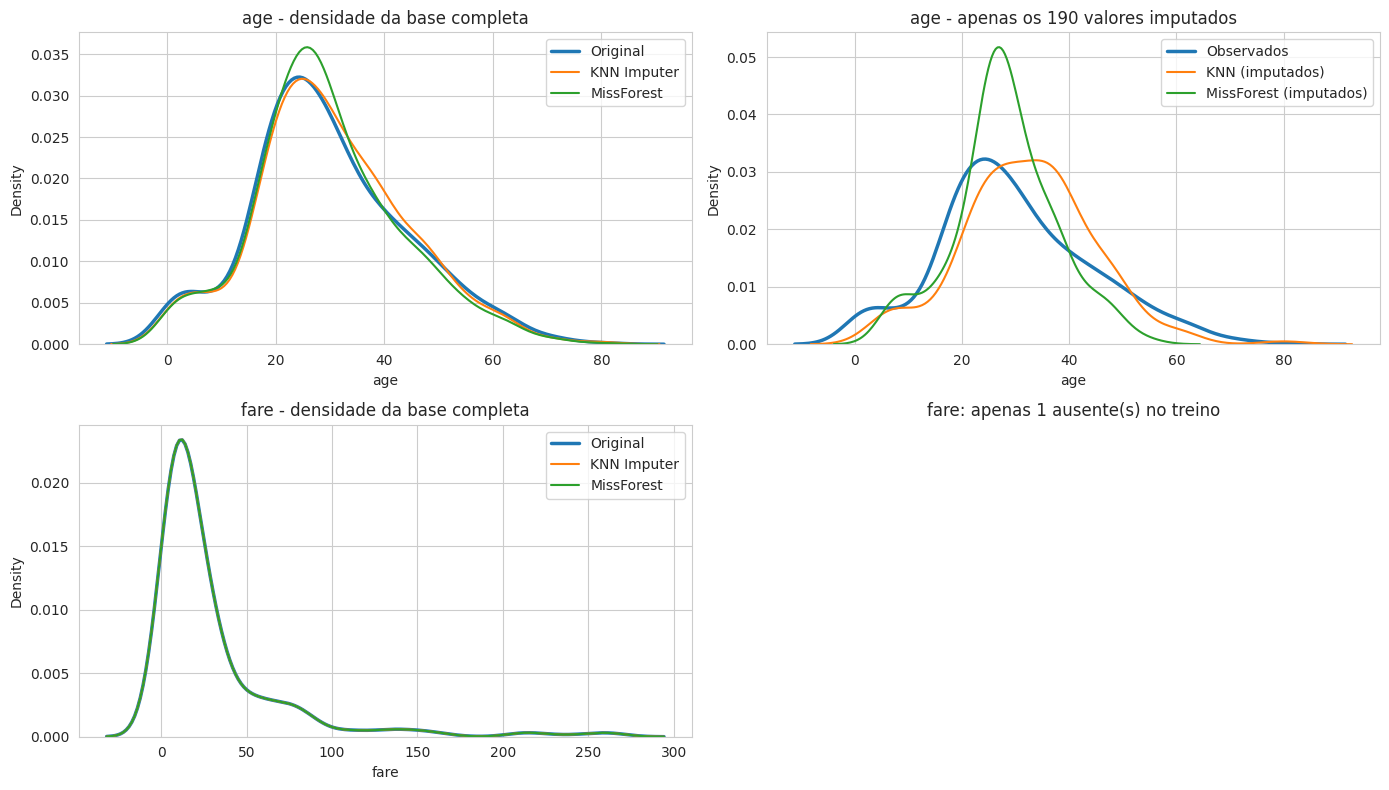

In [13]:
fig, eixos = plt.subplots(2, 2, figsize=(14, 8))
for i, atr in enumerate(['age', 'fare']):
    orig  = X_tr_raw[atr].dropna()
    corte = orig.quantile(.99) if atr == 'fare' else orig.max()
    sns.kdeplot(orig[orig <= corte], label='Original', lw=2.5, ax=eixos[i, 0])
    sns.kdeplot(Xtr_knn[atr][Xtr_knn[atr] <= corte], label='KNN Imputer', ax=eixos[i, 0])
    sns.kdeplot(Xtr_mf[atr][Xtr_mf[atr] <= corte],  label='MissForest',  ax=eixos[i, 0])
    eixos[i, 0].set_title(f'{atr} - densidade da base completa'); eixos[i, 0].legend()

    mask = X_tr_raw[atr].isna()
    if mask.sum() > 3:
        sns.kdeplot(orig[orig <= corte], label='Observados', lw=2.5, ax=eixos[i, 1])
        sns.kdeplot(Xtr_knn.loc[mask, atr], label='KNN (imputados)', ax=eixos[i, 1])
        sns.kdeplot(Xtr_mf.loc[mask, atr],  label='MissForest (imputados)', ax=eixos[i, 1])
        eixos[i, 1].set_title(f'{atr} - apenas os {mask.sum()} valores imputados')
        eixos[i, 1].legend()
    else:
        eixos[i, 1].axis('off')
        eixos[i, 1].set_title(f'{atr}: apenas {mask.sum()} ausente(s) no treino')
plt.tight_layout(); plt.show()

In [14]:
balanceadores = {'SMOTE': SMOTE(random_state=SEED, k_neighbors=5),
                 'RandomUnderSampling': RandomUnderSampler(random_state=SEED)}

linhas, conjuntos = [], {}
for nome_imp, Xtr in [('KNN Imputer', Xtr_knn), ('MissForest', Xtr_mf)]:
    linhas.append({'Imputacao': nome_imp, 'Tecnica': 'Sem balanceamento',
                   'Morreu (0)': int((y_tr == 0).sum()), 'Sobreviveu (1)': int((y_tr == 1).sum()),
                   'Total': len(y_tr),
                   'Razao 0:1': round((y_tr == 0).sum() / (y_tr == 1).sum(), 2),
                   '% minoritaria': round((y_tr == 1).mean() * 100, 1)})
    for nome_bal, tec in balanceadores.items():
        Xb, yb = tec.fit_resample(Xtr, y_tr)
        conjuntos[(nome_imp, nome_bal)] = (Xb, yb)
        linhas.append({'Imputacao': nome_imp, 'Tecnica': nome_bal,
                       'Morreu (0)': int((yb == 0).sum()), 'Sobreviveu (1)': int((yb == 1).sum()),
                       'Total': len(yb),
                       'Razao 0:1': round((yb == 0).sum() / (yb == 1).sum(), 2),
                       '% minoritaria': round((yb == 1).mean() * 100, 1)})

tab_bal = pd.DataFrame(linhas)
print('TABELA 3 - Distribuicao das classes antes e depois do balanceamento (TREINO)')
print(tab_bal.to_string(index=False))
print('\nConjunto de TESTE (nunca balanceado):', dict(y_te.value_counts()))

TABELA 3 - Distribuicao das classes antes e depois do balanceamento (TREINO)
  Imputacao             Tecnica  Morreu (0)  Sobreviveu (1)  Total  Razao 0:1  % minoritaria
KNN Imputer   Sem balanceamento         566             350    916       1.62           38.2
KNN Imputer               SMOTE         566             566   1132       1.00           50.0
KNN Imputer RandomUnderSampling         350             350    700       1.00           50.0
 MissForest   Sem balanceamento         566             350    916       1.62           38.2
 MissForest               SMOTE         566             566   1132       1.00           50.0
 MissForest RandomUnderSampling         350             350    700       1.00           50.0

Conjunto de TESTE (nunca balanceado): {0: np.int64(243), 1: np.int64(150)}


Media dos atributos apos cada tecnica (imputacao KNN):
        Original (treino)  Apos SMOTE  Apos RandomUnder
age                30.322      30.226            30.185
fare               32.555      35.505            35.985
pclass              2.298       2.230             2.246
sibsp               0.481       0.478             0.460


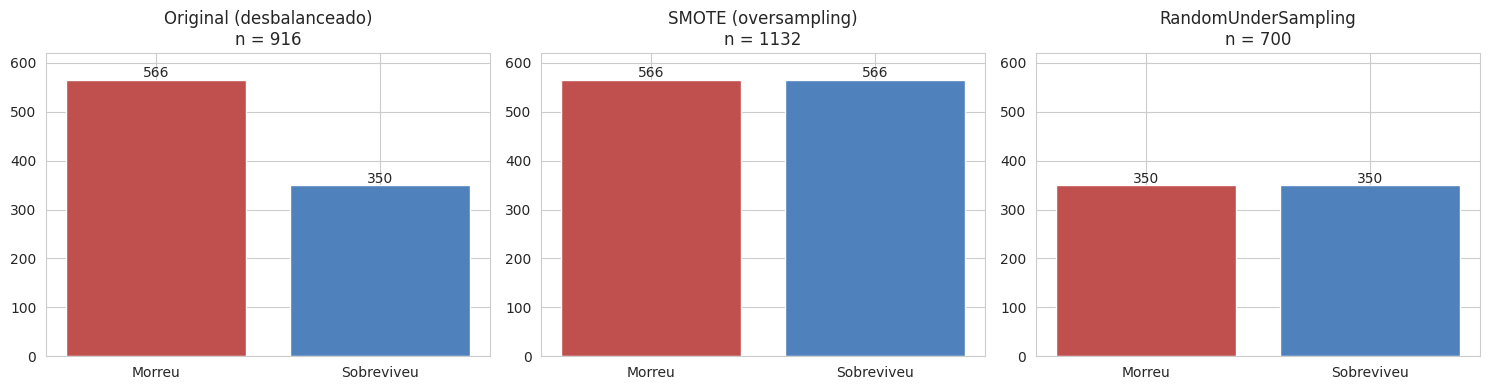

In [15]:
Xs, ys = conjuntos[('KNN Imputer', 'SMOTE')]
Xu, yu = conjuntos[('KNN Imputer', 'RandomUnderSampling')]

comp = pd.DataFrame({
    'Original (treino)' : Xtr_knn[['age', 'fare', 'pclass', 'sibsp']].mean(),
    'Apos SMOTE'        : Xs[['age', 'fare', 'pclass', 'sibsp']].mean(),
    'Apos RandomUnder'  : Xu[['age', 'fare', 'pclass', 'sibsp']].mean(),
}).round(3)
print('Media dos atributos apos cada tecnica (imputacao KNN):')
print(comp.to_string())

fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
for ax, (titulo, yy) in zip(eixos, [('Original (desbalanceado)', y_tr),
                                    ('SMOTE (oversampling)', ys),
                                    ('RandomUnderSampling', yu)]):
    vc = pd.Series(yy).value_counts().sort_index()
    ax.bar(['Morreu', 'Sobreviveu'], vc.values, color=['#c0504d', '#4f81bd'])
    for i, v in enumerate(vc.values):
        ax.text(i, v + 5, str(v), ha='center')
    ax.set_title(f'{titulo}\nn = {len(yy)}'); ax.set_ylim(0, 620)
plt.tight_layout(); plt.show()

In [16]:
Xtr_ref = Xtr_knn          # combinacao de referencia para a busca: KNN + SMOTE

def pipe(modelo):
    return Pipeline([('bal', SMOTE(random_state=SEED)), ('clf', modelo)])

resultados = {}

espaco_rs_ad = {
    'clf__criterion'        : ['gini', 'entropy'],
    'clf__max_depth'        : [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None],
    'clf__min_samples_split': randint(2, 40),
    'clf__min_samples_leaf' : randint(1, 30),
    'clf__max_features'     : [None, 'sqrt', 'log2'],
}
espaco_rs_rf = {
    'clf__n_estimators'     : randint(50, 500),
    'clf__criterion'        : ['gini', 'entropy'],
    'clf__max_depth'        : [3, 5, 8, 10, 12, 15, 20, None],
    'clf__min_samples_split': randint(2, 30),
    'clf__min_samples_leaf' : randint(1, 20),
    'clf__max_features'     : ['sqrt', 'log2', None],
}

def random_search(nome, modelo, espaco, n_iter=60):
    busca = RandomizedSearchCV(pipe(modelo), espaco, n_iter=n_iter, cv=CV,
                               scoring=METRICA, random_state=SEED, n_jobs=-1)
    t0 = time.perf_counter(); busca.fit(Xtr_ref, y_tr); t = time.perf_counter() - t0
    par = {k.replace('clf__', ''): v for k, v in busca.best_params_.items()}
    resultados[nome] = {'params': par, 'score': busca.best_score_, 'tempo': t, 'n_aval': n_iter}
    print(f'[{nome}]  tempo = {t:.2f}s  |  F1 (CV) = {busca.best_score_:.4f}')
    print('   ->', par, '\n')

random_search('AD - Random Search', DecisionTreeClassifier(random_state=SEED), espaco_rs_ad)
random_search('RF - Random Search', RandomForestClassifier(random_state=SEED, n_jobs=-1), espaco_rs_rf)

[AD - Random Search]  tempo = 2.12s  |  F1 (CV) = 0.7155
   -> {'criterion': 'gini', 'max_depth': 4, 'max_features': 'log2', 'min_samples_leaf': 6, 'min_samples_split': 9} 



[RF - Random Search]  tempo = 86.19s  |  F1 (CV) = 0.7261
   -> {'criterion': 'entropy', 'max_depth': 15, 'max_features': None, 'min_samples_leaf': 7, 'min_samples_split': 2, 'n_estimators': 434} 



In [17]:
def objetivo_ad(trial):
    m = DecisionTreeClassifier(
        criterion        = trial.suggest_categorical('criterion', ['gini', 'entropy']),
        max_depth        = trial.suggest_int('max_depth', 2, 20),
        min_samples_split= trial.suggest_int('min_samples_split', 2, 40),
        min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 30),
        max_features     = trial.suggest_categorical('max_features', [None, 'sqrt', 'log2']),
        random_state=SEED)
    return cross_val_score(pipe(m), Xtr_ref, y_tr, cv=CV, scoring=METRICA, n_jobs=-1).mean()

def objetivo_rf(trial):
    m = RandomForestClassifier(
        n_estimators     = trial.suggest_int('n_estimators', 50, 500),
        criterion        = trial.suggest_categorical('criterion', ['gini', 'entropy']),
        max_depth        = trial.suggest_int('max_depth', 3, 20),
        min_samples_split= trial.suggest_int('min_samples_split', 2, 30),
        min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 20),
        max_features     = trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        random_state=SEED, n_jobs=-1)
    return cross_val_score(pipe(m), Xtr_ref, y_tr, cv=CV, scoring=METRICA, n_jobs=-1).mean()

def bayesiana(nome, objetivo, n_trials=60):
    est = optuna.create_study(direction='maximize',
                              sampler=optuna.samplers.TPESampler(seed=SEED))
    t0 = time.perf_counter(); est.optimize(objetivo, n_trials=n_trials); t = time.perf_counter() - t0
    resultados[nome] = {'params': est.best_params, 'score': est.best_value,
                        'tempo': t, 'n_aval': n_trials}
    print(f'[{nome}]  tempo = {t:.2f}s  |  F1 (CV) = {est.best_value:.4f}')
    print('   ->', est.best_params, '\n')
    return est

est_ad = bayesiana('AD - Optuna (Bayesiana)', objetivo_ad)
est_rf = bayesiana('RF - Optuna (Bayesiana)', objetivo_rf)

[AD - Optuna (Bayesiana)]  tempo = 2.86s  |  F1 (CV) = 0.7254
   -> {'criterion': 'entropy', 'max_depth': 6, 'min_samples_split': 17, 'min_samples_leaf': 7, 'max_features': None} 



[RF - Optuna (Bayesiana)]  tempo = 116.60s  |  F1 (CV) = 0.7315
   -> {'n_estimators': 380, 'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 16, 'min_samples_leaf': 3, 'max_features': None} 



In [18]:
linhas = []
for nome, r in resultados.items():
    mod, otim = nome.split(' - ')
    linhas.append({'Modelo': 'Arvore de Decisao' if mod == 'AD' else 'Random Forest',
                   'Otimizador': otim, 'Avaliacoes': r['n_aval'],
                   'F1 (CV 5-fold)': round(r['score'], 4),
                   'Tempo (s)': round(r['tempo'], 2),
                   'Tempo/avaliacao (s)': round(r['tempo'] / r['n_aval'], 3),
                   'Hiperparametros': json.dumps(r['params'], default=str)})
tab_otim = pd.DataFrame(linhas)
print('TABELA 4 - Comparacao dos otimizadores de hiperparametros')
print(tab_otim.drop(columns='Hiperparametros').to_string(index=False))
print()
for l in linhas:
    print(f"{l['Modelo']:<18} | {l['Otimizador']:<18} -> {l['Hiperparametros']}")

TABELA 4 - Comparacao dos otimizadores de hiperparametros
           Modelo         Otimizador  Avaliacoes  F1 (CV 5-fold)  Tempo (s)  Tempo/avaliacao (s)
Arvore de Decisao      Random Search          60          0.7155       2.12                0.035
    Random Forest      Random Search          60          0.7261      86.19                1.436
Arvore de Decisao Optuna (Bayesiana)          60          0.7254       2.86                0.048
    Random Forest Optuna (Bayesiana)          60          0.7315     116.60                1.943

Arvore de Decisao  | Random Search      -> {"criterion": "gini", "max_depth": 4, "max_features": "log2", "min_samples_leaf": 6, "min_samples_split": 9}
Random Forest      | Random Search      -> {"criterion": "entropy", "max_depth": 15, "max_features": null, "min_samples_leaf": 7, "min_samples_split": 2, "n_estimators": 434}
Arvore de Decisao  | Optuna (Bayesiana) -> {"criterion": "entropy", "max_depth": 6, "min_samples_split": 17, "min_samples_leaf": 

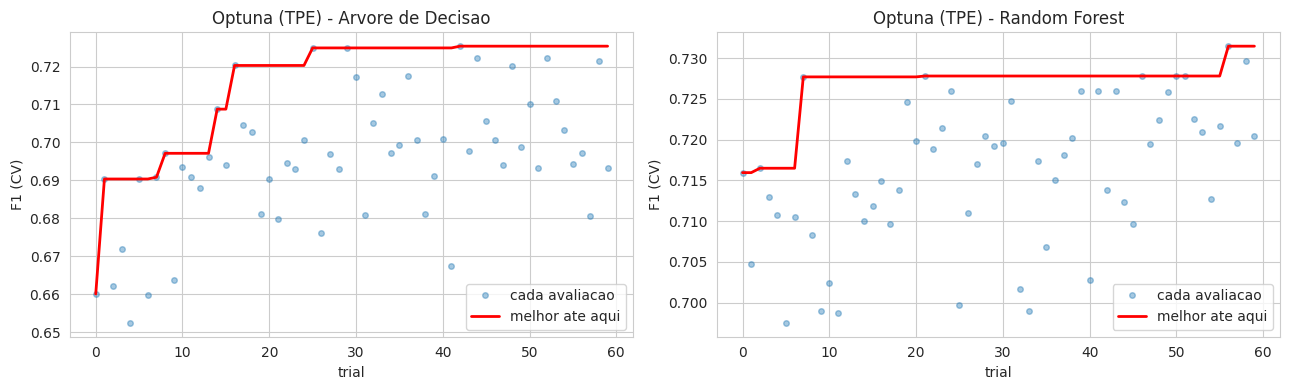

In [19]:
# evolucao da busca bayesiana: o TPE melhora ao longo dos trials?
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for ax, (titulo, est) in zip(eixos, [('Arvore de Decisao', est_ad), ('Random Forest', est_rf)]):
    vals = [t.value for t in est.trials]
    ax.plot(vals, 'o', alpha=.4, ms=4, label='cada avaliacao')
    ax.plot(np.maximum.accumulate(vals), lw=2, color='red', label='melhor ate aqui')
    ax.set_title(f'Optuna (TPE) - {titulo}'); ax.set_xlabel('trial'); ax.set_ylabel('F1 (CV)')
    ax.legend()
plt.tight_layout(); plt.show()

In [20]:
def melhor(prefixo):
    cands = {k: v for k, v in resultados.items() if k.startswith(prefixo)}
    return max(cands.items(), key=lambda kv: kv[1]['score'])

nome_ad, best_ad = melhor('AD')
nome_rf, best_rf = melhor('RF')
P_AD, P_RF = dict(best_ad['params']), dict(best_rf['params'])
print('Hiperparametros adotados:')
print('  Arvore de Decisao ->', nome_ad, P_AD)
print('  Random Forest     ->', nome_rf, P_RF)

Hiperparametros adotados:
  Arvore de Decisao -> AD - Optuna (Bayesiana) {'criterion': 'entropy', 'max_depth': 6, 'min_samples_split': 17, 'min_samples_leaf': 7, 'max_features': None}
  Random Forest     -> RF - Optuna (Bayesiana) {'n_estimators': 380, 'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 16, 'min_samples_leaf': 3, 'max_features': None}


In [21]:
def metricas(modelo, Xtr, ytr, Xte, yte):
    pr_te, pr_tr = modelo.predict(Xte), modelo.predict(Xtr)
    prob = modelo.predict_proba(Xte)[:, 1]
    return {'Acuracia (treino)': accuracy_score(ytr, pr_tr),
            'Acuracia'         : accuracy_score(yte, pr_te),
            'Precisao'         : precision_score(yte, pr_te),
            'Recall'           : recall_score(yte, pr_te),
            'F1'               : f1_score(yte, pr_te),
            'F1 macro'         : f1_score(yte, pr_te, average='macro'),
            'AUC'              : roc_auc_score(yte, prob),
            'Gap treino-teste' : accuracy_score(ytr, pr_tr) - accuracy_score(yte, pr_te)}

imputacoes = {'KNN Imputer': (Xtr_knn, Xte_knn), 'MissForest': (Xtr_mf, Xte_mf)}
linhas, modelos = [], {}

for nome_imp, (Xtr, Xte) in imputacoes.items():
    for nome_bal in balanceadores:
        Xb, yb = conjuntos[(nome_imp, nome_bal)]
        for nome_mod, modelo in [
            ('Arvore de Decisao', DecisionTreeClassifier(random_state=SEED, **P_AD)),
            ('Random Forest',     RandomForestClassifier(random_state=SEED, n_jobs=-1, **P_RF))]:
            modelo.fit(Xb, yb)
            modelos[(nome_imp, nome_bal, nome_mod)] = (modelo, Xb, yb, Xte)
            linhas.append({'Imputacao': nome_imp, 'Balanceamento': nome_bal, 'Modelo': nome_mod,
                           **{k: round(v, 4) for k, v in metricas(modelo, Xb, yb, Xte, y_te).items()}})

tab = pd.DataFrame(linhas)
print('TABELA 5 - Desempenho no conjunto de TESTE (classe positiva = Sobreviveu)')
print(tab.to_string(index=False))

TABELA 5 - Desempenho no conjunto de TESTE (classe positiva = Sobreviveu)
  Imputacao       Balanceamento            Modelo  Acuracia (treino)  Acuracia  Precisao  Recall     F1  F1 macro    AUC  Gap treino-teste
KNN Imputer               SMOTE Arvore de Decisao             0.8383    0.8244    0.7682  0.7733 0.7708    0.8142 0.8618            0.0139
KNN Imputer               SMOTE     Random Forest             0.8136    0.8346    0.7972  0.7600 0.7782    0.8232 0.8889           -0.0210
KNN Imputer RandomUnderSampling Arvore de Decisao             0.8300    0.8066    0.7229  0.8000 0.7595    0.7989 0.8408            0.0234
KNN Imputer RandomUnderSampling     Random Forest             0.8000    0.8346    0.7931  0.7667 0.7797    0.8236 0.8850           -0.0346
 MissForest               SMOTE Arvore de Decisao             0.8313    0.8092    0.7551  0.7400 0.7475    0.7971 0.8497            0.0221
 MissForest               SMOTE     Random Forest             0.8127    0.8346    0.8014  0.

In [22]:
print('Media por MODELO:')
print(tab.groupby('Modelo')[['Acuracia', 'Precisao', 'Recall', 'F1', 'AUC',
                             'Gap treino-teste']].mean().round(4).to_string())
print('\nMedia por METODO DE IMPUTACAO:')
print(tab.groupby('Imputacao')[['Acuracia', 'Precisao', 'Recall', 'F1', 'AUC']].mean().round(4).to_string())
print('\nMedia por TECNICA DE BALANCEAMENTO:')
print(tab.groupby('Balanceamento')[['Acuracia', 'Precisao', 'Recall', 'F1', 'AUC']].mean().round(4).to_string())

Media por MODELO:
                   Acuracia  Precisao  Recall      F1     AUC  Gap treino-teste
Modelo                                                                         
Arvore de Decisao    0.8162    0.7519  0.7750  0.7629  0.8563            0.0173
Random Forest        0.8340    0.7969  0.7583  0.7771  0.8854           -0.0274

Media por METODO DE IMPUTACAO:
             Acuracia  Precisao  Recall     F1     AUC
Imputacao                                             
KNN Imputer    0.8250    0.7704  0.7750  0.772  0.8691
MissForest     0.8251    0.7784  0.7583  0.768  0.8726

Media por TECNICA DE BALANCEAMENTO:
                     Acuracia  Precisao  Recall      F1     AUC
Balanceamento                                                  
RandomUnderSampling    0.8244    0.7683  0.7767  0.7717  0.8709
SMOTE                  0.8257    0.7805  0.7566  0.7683  0.8708


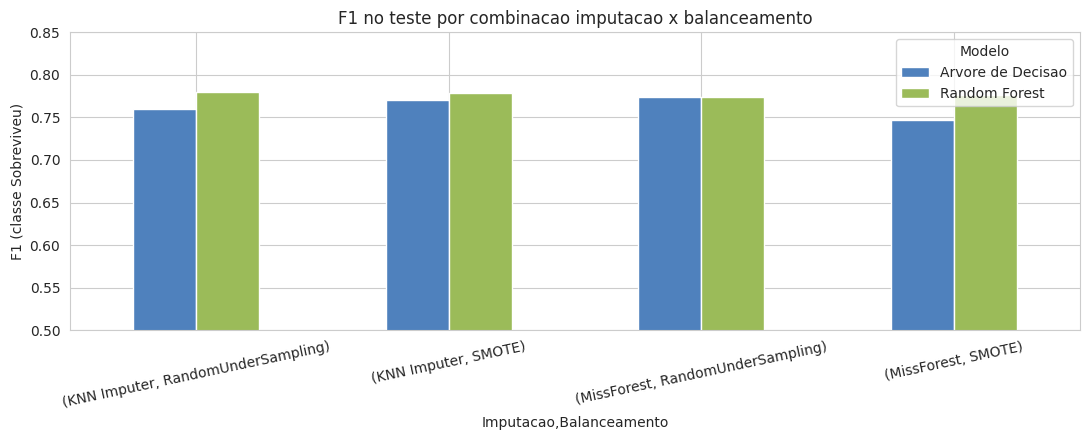

In [23]:
fig, ax = plt.subplots(figsize=(11, 4.5))
tab.pivot_table(index=['Imputacao', 'Balanceamento'], columns='Modelo', values='F1')\
   .plot(kind='bar', ax=ax, rot=12, color=['#4f81bd', '#9bbb59'])
ax.set_ylabel('F1 (classe Sobreviveu)'); ax.set_ylim(0.5, 0.85)
ax.set_title('F1 no teste por combinacao imputacao x balanceamento')
plt.tight_layout(); plt.show()

Melhor AD: MissForest + RandomUnderSampling | acuracia = 0.8244 | F1 = 0.7738
Melhor RF: KNN Imputer + RandomUnderSampling | acuracia = 0.8346 | F1 = 0.7797

Relatorio - Arvore de Decisao:
              precision    recall  f1-score   support

      Morreu      0.866     0.848     0.857       243
  Sobreviveu      0.761     0.787     0.774       150

    accuracy                          0.824       393
   macro avg      0.813     0.817     0.815       393
weighted avg      0.826     0.824     0.825       393

Relatorio - Random Forest:
              precision    recall  f1-score   support

      Morreu      0.859     0.877     0.868       243
  Sobreviveu      0.793     0.767     0.780       150

    accuracy                          0.835       393
   macro avg      0.826     0.822     0.824       393
weighted avg      0.834     0.835     0.834       393



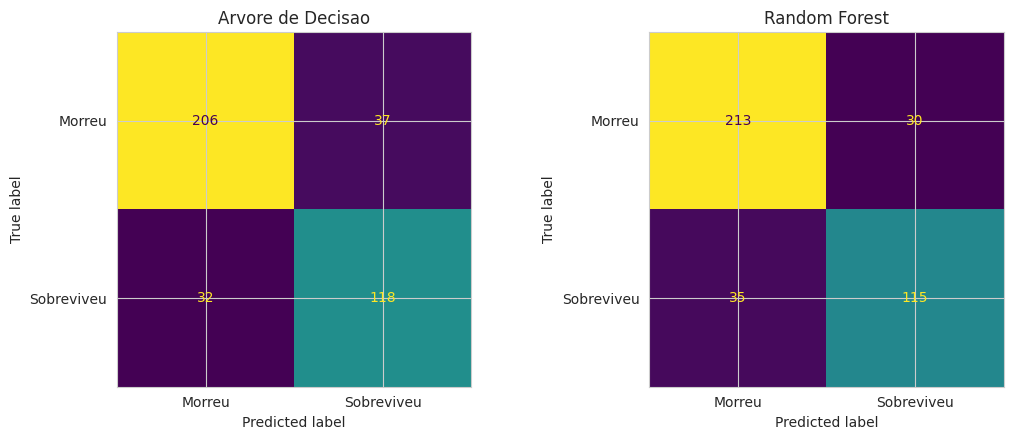

In [24]:
melhor_ad = tab[tab.Modelo == 'Arvore de Decisao'].sort_values('F1', ascending=False).iloc[0]
melhor_rf = tab[tab.Modelo == 'Random Forest'].sort_values('F1', ascending=False).iloc[0]
print('Melhor AD:', melhor_ad.Imputacao, '+', melhor_ad.Balanceamento,
      '| acuracia =', melhor_ad.Acuracia, '| F1 =', melhor_ad.F1)
print('Melhor RF:', melhor_rf.Imputacao, '+', melhor_rf.Balanceamento,
      '| acuracia =', melhor_rf.Acuracia, '| F1 =', melhor_rf.F1)

mod_ad, Xb_ad, yb_ad, Xte_ad = modelos[(melhor_ad.Imputacao, melhor_ad.Balanceamento, 'Arvore de Decisao')]
mod_rf, Xb_rf, yb_rf, Xte_rf = modelos[(melhor_rf.Imputacao, melhor_rf.Balanceamento, 'Random Forest')]

print('\nRelatorio - Arvore de Decisao:')
print(classification_report(y_te, mod_ad.predict(Xte_ad),
                            target_names=['Morreu', 'Sobreviveu'], digits=3))
print('Relatorio - Random Forest:')
print(classification_report(y_te, mod_rf.predict(Xte_rf),
                            target_names=['Morreu', 'Sobreviveu'], digits=3))

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (titulo, mod, Xte) in zip(eixos, [('Arvore de Decisao', mod_ad, Xte_ad),
                                          ('Random Forest', mod_rf, Xte_rf)]):
    ConfusionMatrixDisplay(confusion_matrix(y_te, mod.predict(Xte)),
                           display_labels=['Morreu', 'Sobreviveu']).plot(ax=ax, colorbar=False)
    ax.set_title(titulo)
plt.tight_layout(); plt.show()

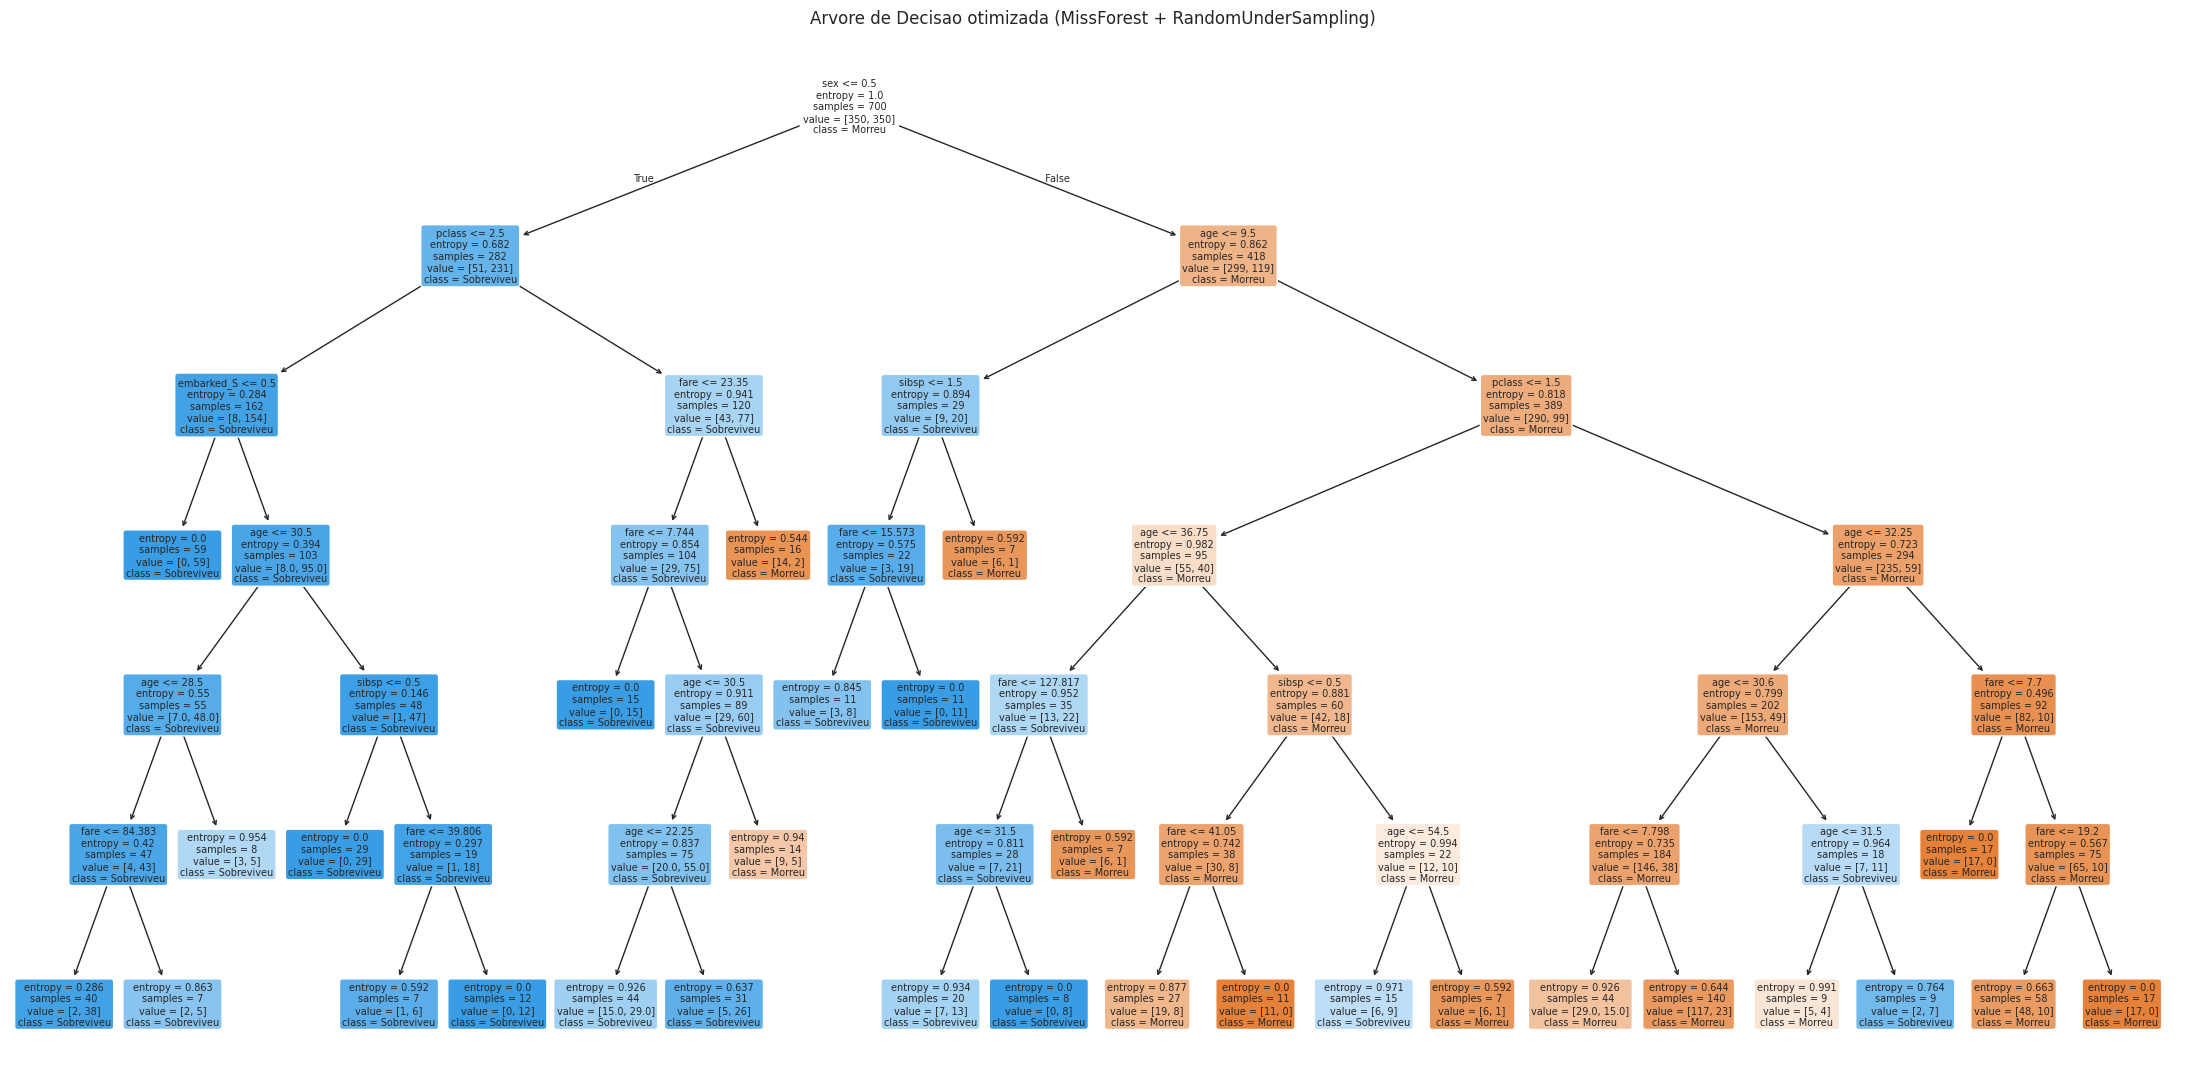

|--- sex <= 0.50
|   |--- pclass <= 2.50
|   |   |--- embarked_S <= 0.50
|   |   |   |--- class: 1
|   |   |--- embarked_S >  0.50
|   |   |   |--- age <= 30.50
|   |   |   |   |--- age <= 28.50
|   |   |   |   |   |--- fare <= 84.38
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- fare >  84.38
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- age >  28.50
|   |   |   |   |   |--- class: 1
|   |   |   |--- age >  30.50
|   |   |   |   |--- sibsp <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- sibsp >  0.50
|   |   |   |   |   |--- fare <= 39.81
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- fare >  39.81
|   |   |   |   |   |   |--- class: 1
|   |--- pclass >  2.50
|   |   |--- fare <= 23.35
|   |   |   |--- fare <= 7.74
|   |   |   |   |--- class: 1
|   |   |   |--- fare >  7.74
|   |   |   |   |--- age <= 30.50
|   |   |   |   |   |--- age <= 22.25
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- age >  22.25
|   | 

In [25]:
plt.figure(figsize=(22, 11))
plot_tree(mod_ad, feature_names=COLS, class_names=['Morreu', 'Sobreviveu'],
          filled=True, rounded=True, fontsize=7)
plt.title(f'Arvore de Decisao otimizada ({melhor_ad.Imputacao} + {melhor_ad.Balanceamento})')
plt.tight_layout(); plt.show()

print(export_text(mod_ad, feature_names=COLS, decimals=2))

In [26]:
def extrair_regras(modelo, colunas):
    """Percorre a arvore e devolve uma regra por folha, com cobertura e confianca."""
    arvore, regras = modelo.tree_, []
    n_total = modelo.tree_.n_node_samples[0]

    def traduzir(coluna, limiar, esquerda):
        if coluna == 'sex':
            return 'sex = feminino' if esquerda else 'sex = masculino'
        if coluna.startswith('embarked_'):
            porto = coluna.split('_')[1]
            return f'embarked != {porto}' if esquerda else f'embarked = {porto}'
        if coluna == 'pclass':
            corte = int(np.floor(limiar))
            return f'pclass <= {corte}' if esquerda else f'pclass >= {corte + 1}'
        return f'{coluna} <= {limiar:.2f}' if esquerda else f'{coluna} > {limiar:.2f}'

    def percorrer(no, cond):
        if arvore.feature[no] == -2:
            n = int(arvore.n_node_samples[no])
            dist = np.round(arvore.value[no][0] * n).astype(int)
            classe = int(np.argmax(dist))
            regras.append({'regra': ' E '.join(cond),
                           'classe': 'SOBREVIVEU' if classe else 'MORREU',
                           'n': n, 'cobertura': n / n_total,
                           'confianca': dist[classe] / dist.sum()})
            return
        col, lim = colunas[arvore.feature[no]], arvore.threshold[no]
        percorrer(arvore.children_left[no],  cond + [traduzir(col, lim, True)])
        percorrer(arvore.children_right[no], cond + [traduzir(col, lim, False)])

    percorrer(0, [])
    return (pd.DataFrame(regras).sort_values('cobertura', ascending=False)
              .reset_index(drop=True))

regras = extrair_regras(mod_ad, COLS)
print(f'A arvore otimizada tem {mod_ad.get_n_leaves()} folhas, logo {len(regras)} regras.')
print('\nAs 10 regras de maior cobertura:\n')
for i, r in regras.head(10).iterrows():
    print(f"R{i+1}: SE {r['regra']}\n     ENTAO {r['classe']}"
          f"  (cobertura = {r['cobertura']:.1%}, {r['n']} exemplos"
          f" | confianca = {r['confianca']:.1%})\n")

A arvore otimizada tem 29 folhas, logo 29 regras.

As 10 regras de maior cobertura:

R1: SE sex = masculino E age > 9.50 E pclass >= 2 E age <= 32.25 E age <= 30.60 E fare > 7.80
     ENTAO MORREU  (cobertura = 20.0%, 140 exemplos | confianca = 83.6%)

R2: SE sex = feminino E pclass <= 2 E embarked != S
     ENTAO SOBREVIVEU  (cobertura = 8.4%, 59 exemplos | confianca = 100.0%)

R3: SE sex = masculino E age > 9.50 E pclass >= 2 E age > 32.25 E fare > 7.70 E fare <= 19.20
     ENTAO MORREU  (cobertura = 8.3%, 58 exemplos | confianca = 82.8%)

R4: SE sex = feminino E pclass >= 3 E fare <= 23.35 E fare > 7.74 E age <= 30.50 E age <= 22.25
     ENTAO SOBREVIVEU  (cobertura = 6.3%, 44 exemplos | confianca = 65.9%)

R5: SE sex = masculino E age > 9.50 E pclass >= 2 E age <= 32.25 E age <= 30.60 E fare <= 7.80
     ENTAO MORREU  (cobertura = 6.3%, 44 exemplos | confianca = 65.9%)

R6: SE sex = feminino E pclass <= 2 E embarked = S E age <= 30.50 E age <= 28.50 E fare <= 84.38
     ENTAO SOBRE

Arvore interpretavel (max_depth = 3):
{'Acuracia (treino)': 0.7971, 'Acuracia': 0.8346, 'Precisao': 0.8014, 'Recall': 0.7533, 'F1': 0.7766, 'F1 macro': 0.8227, 'AUC': 0.8846, 'Gap treino-teste': -0.0375}

Folhas: 8 (contra 29 da arvore otimizada)


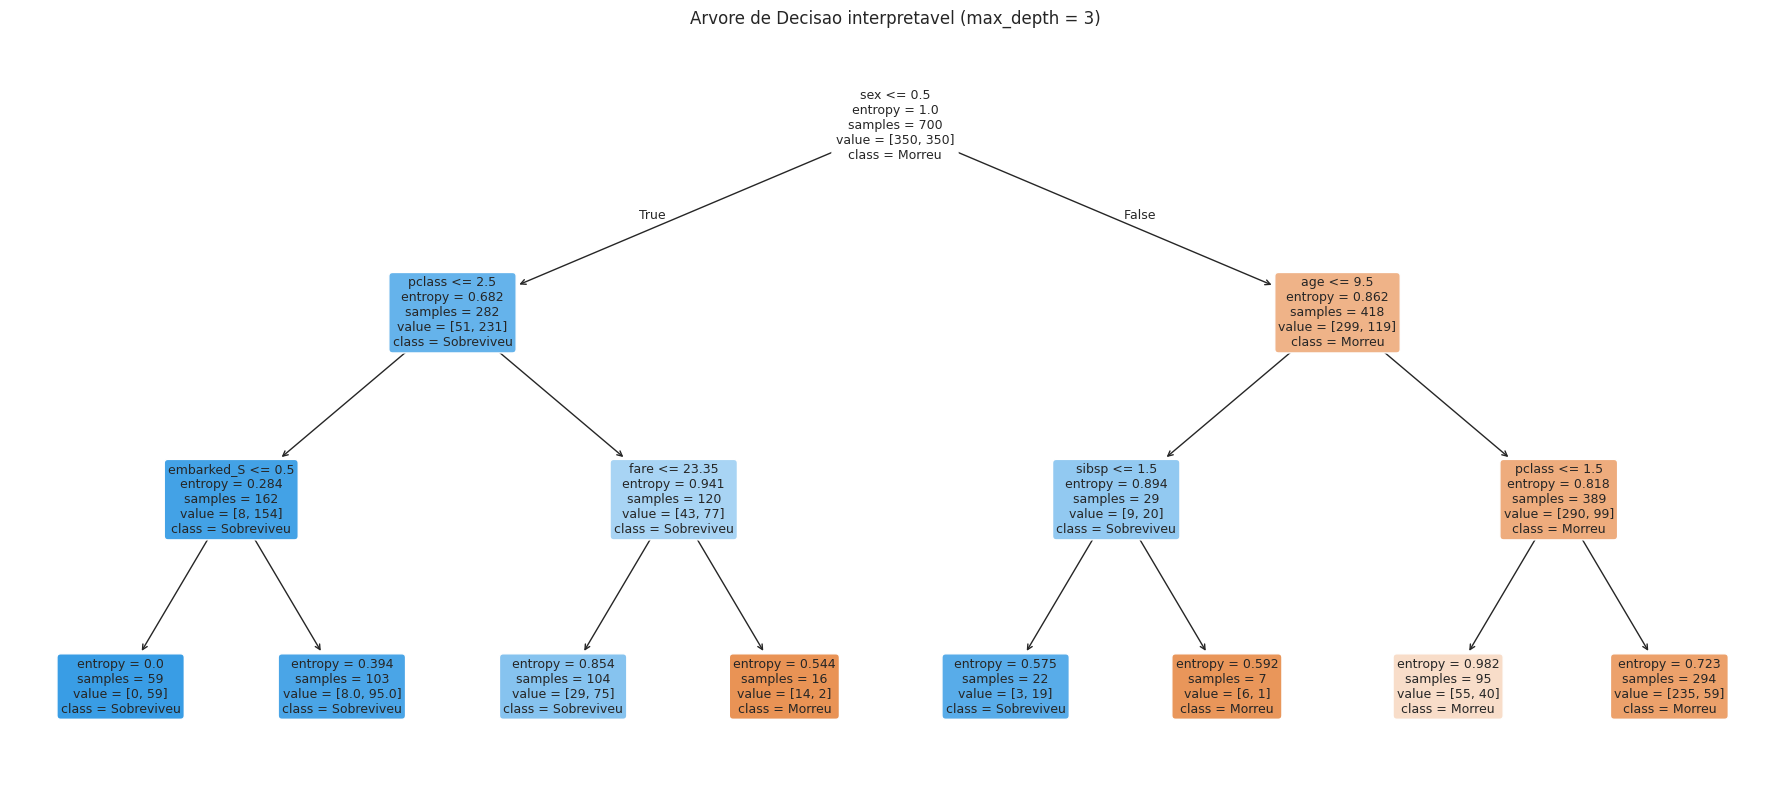

In [27]:
P_INT = dict(P_AD); P_INT['max_depth'] = 3
ad_int = DecisionTreeClassifier(random_state=SEED, **P_INT).fit(Xb_ad, yb_ad)
m_int  = metricas(ad_int, Xb_ad, yb_ad, Xte_ad, y_te)

print('Arvore interpretavel (max_depth = 3):')
print({k: round(v, 4) for k, v in m_int.items()})
print(f'\nFolhas: {ad_int.get_n_leaves()} (contra {mod_ad.get_n_leaves()} da arvore otimizada)')

plt.figure(figsize=(18, 8))
plot_tree(ad_int, feature_names=COLS, class_names=['Morreu', 'Sobreviveu'],
          filled=True, rounded=True, fontsize=9)
plt.title('Arvore de Decisao interpretavel (max_depth = 3)')
plt.tight_layout(); plt.show()

In [28]:
regras_int = extrair_regras(ad_int, COLS)
print('REGRAS DO PADRAO DE SOBREVIVENCIA\n' + '=' * 70)
for i, r in regras_int.iterrows():
    print(f"\nR{i+1}: SE {r['regra']}")
    print(f"     ENTAO {r['classe']}")
    print(f"     cobertura = {r['cobertura']:.1%} ({r['n']} exemplos)"
          f" | confianca = {r['confianca']:.1%}")

tabela_regras = regras_int.assign(
    cobertura=lambda d: (d.cobertura * 100).round(1),
    confianca=lambda d: (d.confianca * 100).round(1))
tabela_regras.index = [f'R{i+1}' for i in range(len(tabela_regras))]
print('\n\nTABELA 6 - Regras, cobertura e confianca')
print(tabela_regras.to_string())

REGRAS DO PADRAO DE SOBREVIVENCIA

R1: SE sex = masculino E age > 9.50 E pclass >= 2
     ENTAO MORREU
     cobertura = 42.0% (294 exemplos) | confianca = 79.9%

R2: SE sex = feminino E pclass >= 3 E fare <= 23.35
     ENTAO SOBREVIVEU
     cobertura = 14.9% (104 exemplos) | confianca = 72.1%

R3: SE sex = feminino E pclass <= 2 E embarked = S
     ENTAO SOBREVIVEU
     cobertura = 14.7% (103 exemplos) | confianca = 92.2%

R4: SE sex = masculino E age > 9.50 E pclass <= 1
     ENTAO MORREU
     cobertura = 13.6% (95 exemplos) | confianca = 57.9%

R5: SE sex = feminino E pclass <= 2 E embarked != S
     ENTAO SOBREVIVEU
     cobertura = 8.4% (59 exemplos) | confianca = 100.0%

R6: SE sex = masculino E age <= 9.50 E sibsp <= 1.50
     ENTAO SOBREVIVEU
     cobertura = 3.1% (22 exemplos) | confianca = 86.4%

R7: SE sex = feminino E pclass >= 3 E fare > 23.35
     ENTAO MORREU
     cobertura = 2.3% (16 exemplos) | confianca = 87.5%

R8: SE sex = masculino E age <= 9.50 E sibsp > 1.50
     

TABELA 7 - Importancia dos atributos
  Atributo  Arvore de Decisao  Random Forest
       sex             0.4545         0.6549
    pclass             0.1411         0.1103
       age             0.1845         0.0903
      fare             0.1624         0.0888
     sibsp             0.0409         0.0324
embarked_C             0.0000         0.0207
     parch             0.0000         0.0018
embarked_S             0.0166         0.0007
embarked_Q             0.0000         0.0001


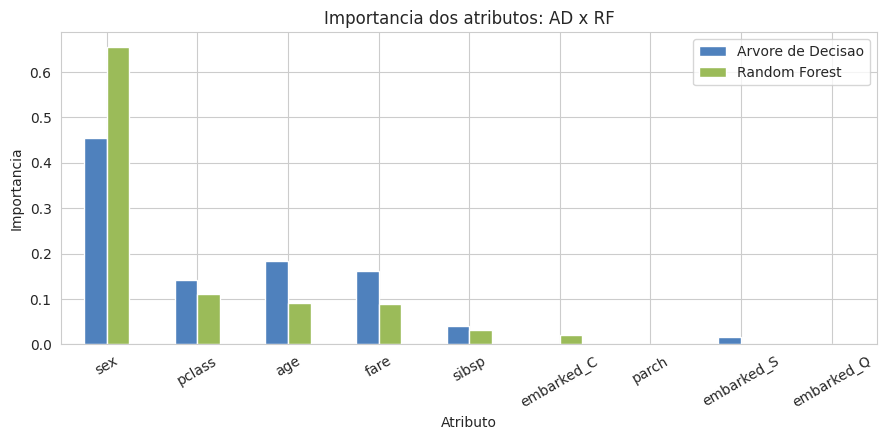


Interpretabilidade:
  Arvore interpretavel : 8 regras
  Arvore otimizada     : 29 regras
  Random Forest        : 380 arvores, 2947 folhas no total -> 2947 regras


In [29]:
imp = pd.DataFrame({'Atributo': COLS,
                    'Arvore de Decisao': mod_ad.feature_importances_,
                    'Random Forest': mod_rf.feature_importances_}) \
       .sort_values('Random Forest', ascending=False).round(4)
print('TABELA 7 - Importancia dos atributos')
print(imp.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
imp.set_index('Atributo').plot(kind='bar', ax=ax, rot=30, color=['#4f81bd', '#9bbb59'])
ax.set_ylabel('Importancia'); ax.set_title('Importancia dos atributos: AD x RF')
plt.tight_layout(); plt.show()

folhas_rf = sum(e.get_n_leaves() for e in mod_rf.estimators_)
print(f'\nInterpretabilidade:')
print(f'  Arvore interpretavel : {ad_int.get_n_leaves()} regras')
print(f'  Arvore otimizada     : {mod_ad.get_n_leaves()} regras')
print(f'  Random Forest        : {len(mod_rf.estimators_)} arvores, '
      f'{folhas_rf} folhas no total -> {folhas_rf} regras')